# Notebook 1 — Data Cleaning and First Models for HEA Yield Strength

**Project:** *Machine learning for the yield strength of high-entropy alloys (HEAs): honest validation and hardness-to-strength transfer*

### What this notebook does

In this first notebook we will:

1. **Download** a public dataset of high-entropy alloy mechanical properties.
2. **Clean** it so that we keep only trustworthy, comparable measurements.
3. **Count duplicates**, meaning how often the *same alloy* appears more than once.
4. **Compute physics-based features** (descriptors) from each alloy's composition.
5. **Train simple ML models** to predict yield strength.
6. **Compare three ways of testing the models**, a random split and two "honest" grouped splits, and see how much the accuracy changes.
7. **Check the hardness data**, which tells us whether the main idea of the paper (using hardness to help predict strength) is feasible.
8. **Save** the cleaned data for the next notebooks.

### How to use this notebook

* Run the cells **from top to bottom** (in Jupyter: *Kernel → Restart & Run All*; on Kaggle: *Run All*).
* Read the text cells; they explain *why* each step is done.
* Boxes marked **📝 For your paper** tell you what to write in your manuscript from that step.

### Software you need

Run this once in a terminal or in a notebook cell (on Kaggle most packages are already installed):

```
pip install pandas numpy scikit-learn xgboost matplotlib pymatgen
```

## Step 1 — Import the libraries

A *library* is a ready-made toolbox of Python code. We import everything at the top so that it's easy to see what the notebook depends on.

In [1]:
# --- Standard Python tools ---
import os                      # work with files and folders
import re                      # "regular expressions": find patterns inside text
import urllib.request          # download a file from the internet
import warnings                # used to hide harmless warning messages

# --- Data handling ---
import numpy as np             # fast maths on arrays of numbers
import pandas as pd            # tables of data (called "DataFrames")

# --- Plotting ---
import matplotlib.pyplot as plt

# --- Chemistry: element properties (atomic radius, melting point, ...) ---
from pymatgen.core import Element

# --- Machine learning (scikit-learn and XGBoost) ---
from sklearn.model_selection import KFold, GroupKFold, cross_val_predict
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor

# A fixed "random seed" makes random steps repeat exactly every time you run the notebook.
# This is important for reproducible research: a reviewer must get the same numbers.
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Show more columns when printing tables
pd.set_option("display.max_columns", 30)

# Consistent colours for all plots in this project
COLOR_BLUE   = "#2a78d6"
COLOR_ORANGE = "#eb6834"
COLOR_GREEN  = "#1baf7a"

print("All libraries imported successfully!")

All libraries imported successfully!


## Step 2 — Download the dataset

We use the **MPEA dataset** published by Borg *et al.*, *Scientific Data* 7, 430 (2020), <https://doi.org/10.1038/s41597-020-00768-9>.
It collects mechanical properties of multi-principal element alloys (which include HEAs) from hundreds of published papers. It is free to use under the Apache-2.0 licence.

The code below downloads the file **only once** and saves it in a folder called `data/`. If the file is already there, it is reused.

In [2]:
# Where the data lives online (official GitHub repository of the dataset)
DATA_URL  = "https://raw.githubusercontent.com/CitrineInformatics/MPEA_dataset/master/MPEA_dataset.csv"

# Where we want to keep it on our own computer
DATA_DIR  = "data"
DATA_FILE = os.path.join(DATA_DIR, "MPEA_dataset.csv")

# Create the "data" folder if it does not exist yet
os.makedirs(DATA_DIR, exist_ok=True)

# Download only if we don't already have the file
if not os.path.exists(DATA_FILE):
    print("Downloading the dataset ...")
    urllib.request.urlretrieve(DATA_URL, DATA_FILE)
    print("Saved to", DATA_FILE)
else:
    print("Dataset already downloaded:", DATA_FILE)

Saved to data/MPEA_dataset.csv


## Step 3 — First look at the data

Always *look* at your data before doing anything else. We check:
* how many rows (measurements) and columns (pieces of information) there are,
* what the columns are called,
* a few example rows.

In [3]:
# Read the CSV file into a pandas DataFrame (a table)
raw = pd.read_csv(DATA_FILE)

print("Number of rows (measurements):", raw.shape[0])
print("Number of columns:", raw.shape[1])
print()
print("Column names:")
for name in raw.columns:
    print("  -", name)

Number of rows (measurements): 1545
Number of columns: 23

Column names:
  - IDENTIFIER: Reference ID
  - FORMULA
  - PROPERTY: Microstructure
  - PROPERTY: Processing method
  - PROPERTY: BCC/FCC/other
  - PROPERTY: grain size ($\mu$m)
  - PROPERTY: Exp. Density (g/cm$^3$)
  - PROPERTY: Calculated Density (g/cm$^3$)
  - PROPERTY: HV
  - PROPERTY: Type of test
  - PROPERTY: Test temperature ($^\circ$C)
  - PROPERTY: YS (MPa)
  - PROPERTY: UTS (MPa)
  - PROPERTY: Elongation (%)
  - PROPERTY: Elongation plastic (%)
  - PROPERTY: Exp. Young modulus (GPa)
  - PROPERTY: Calculated Young modulus (GPa)
  - PROPERTY: O content (wppm)
  - PROPERTY: N content (wppm)
  - PROPERTY: C content (wppm)
  - REFERENCE: doi
  - REFERENCE: year
  - REFERENCE: title


The original column names are long and contain special symbols (like `$\mu$m`). We rename them to short, simple names that are easier to type.

In [4]:
# Dictionary: {original long name: new short name}
rename_map = {
    "IDENTIFIER: Reference ID":                    "ref_id",
    "FORMULA":                                     "formula",
    "PROPERTY: Microstructure":                    "microstructure",
    "PROPERTY: Processing method":                 "processing",
    "PROPERTY: BCC/FCC/other":                     "phase",
    "PROPERTY: grain size ($\\mu$m)":              "grain_size_um",
    "PROPERTY: Exp. Density (g/cm$^3$)":           "density_exp",
    "PROPERTY: Calculated Density (g/cm$^3$)":     "density_calc",
    "PROPERTY: HV":                                "hardness_HV",
    "PROPERTY: Type of test":                      "test_type",
    "PROPERTY: Test temperature ($^\\circ$C)":     "test_temp_C",
    "PROPERTY: YS (MPa)":                          "yield_strength_MPa",
    "PROPERTY: UTS (MPa)":                         "uts_MPa",
    "PROPERTY: Elongation (%)":                    "elongation_pct",
    "PROPERTY: Elongation plastic (%)":            "elongation_plastic_pct",
    "PROPERTY: Exp. Young modulus (GPa)":          "youngs_modulus_exp",
    "PROPERTY: Calculated Young modulus (GPa)":    "youngs_modulus_calc",
    "PROPERTY: O content (wppm)":                  "O_wppm",
    "PROPERTY: N content (wppm)":                  "N_wppm",
    "PROPERTY: C content (wppm)":                  "C_wppm",
    "REFERENCE: doi":                              "doi",
    "REFERENCE: year":                             "year",
    "REFERENCE: title":                            "title",
}
df = raw.rename(columns=rename_map)

# Show the first 5 rows, only the columns we care about most
df[["formula", "processing", "phase", "test_type", "test_temp_C",
    "yield_strength_MPa", "hardness_HV", "doi"]].head()

,formula,processing,phase,test_type,test_temp_C,yield_strength_MPa,hardness_HV,doi
0,Al0.25 Co1 Fe1 Ni1,CAST,FCC,C,25.0,158.0,138.0,10.1016/j.jmmm.2014.07.023
1,Al0.5 Co1 Fe1 Ni1,CAST,other,C,25.0,346.0,212.0,10.1016/j.jmmm.2014.07.023
2,Al0.75 Co1 Fe1 Ni1,CAST,other,C,25.0,794.0,385.0,10.1016/j.jmmm.2014.07.023
3,Al1 Co1 Fe1 Ni1,CAST,BCC,C,25.0,964.0,456.0,10.1016/j.jmmm.2014.07.023
4,Co1 Fe1 Ni1,CAST,FCC,C,25.0,204.0,125.0,10.1016/j.jmmm.2014.07.023


**How to read this table:**
* `formula` gives the alloy composition as molar ratios. For example `Al0.25 Co1 Fe1 Ni1` means 0.25 parts Al to 1 part each of Co, Fe and Ni.
* `test_type`: **C** = compression test, **T** = tension test.
* `test_temp_C`: temperature of the mechanical test in °C.
* `NaN` means "Not a Number", i.e. **missing value**. Many measurements report only some properties.

Let's count how many values are present (not missing) for the most important columns:

In [5]:
important = ["yield_strength_MPa", "hardness_HV", "test_type", "test_temp_C", "processing"]
print(df[important].notna().sum().to_string())

yield_strength_MPa    1067
hardness_HV            530
test_type             1150
test_temp_C           1364
processing            1426


## Step 4 — Clean the data

Data cleaning is the **most important step** of the whole project. ML models learn whatever is in the data, including its mistakes. Our cleaning rules:

| Rule | Why |
|---|---|
| Keep only rows that have a yield strength value | It is the property we want to predict. |
| Keep only **room-temperature** tests (20–30 °C) | Strength changes strongly with temperature; mixing 25 °C and 1000 °C would confuse the model. (High-temperature data can be studied later as an extension.) |
| Keep the test type (compression / tension) as a feature | Compression and tension can give different yield strengths for the same alloy, so the model must know which test was used. |
| Remove physically impossible values | Typing errors in papers sometimes create values like 0 MPa. |

We print the number of rows after **every** rule, because you will report these numbers in your paper.

In [6]:
print("Rows at the start:", len(df))

# Rule 1: yield strength must be present
clean = df[df["yield_strength_MPa"].notna()].copy()
print("After keeping rows with yield strength:", len(clean))

# Rule 2: room-temperature tests only (between 20 and 30 °C)
clean = clean[clean["test_temp_C"].between(20, 30)]
print("After keeping room-temperature tests (20-30 °C):", len(clean))

# Rule 3: fill a missing test type with the word "unknown" instead of deleting the row
clean["test_type"] = clean["test_type"].fillna("unknown")
clean["processing"] = clean["processing"].fillna("unknown")
print("\nTest types:")
print(clean["test_type"].value_counts().to_string())

# Rule 4: remove impossible values (yield strength must be positive and below 5000 MPa)
clean = clean[(clean["yield_strength_MPa"] > 0) & (clean["yield_strength_MPa"] < 5000)]
print("\nAfter removing impossible values:", len(clean))

# Reset the row numbers to 0, 1, 2, ... (just for tidiness)
clean = clean.reset_index(drop=True)

Rows at the start: 1545
After keeping rows with yield strength: 1067
After keeping room-temperature tests (20-30 °C): 722

Test types:
test_type
C    435
T    287

After removing impossible values: 722


### Step 4b — Turn the formula text into numbers

A computer cannot learn from the text `"Al0.25 Co1 Fe1 Ni1"` directly. We convert it into **atomic fractions** (each element's share of the atoms, adding up to 1).

Example: `Al0.25 Co1 Fe1 Ni1` → total = 3.25 parts → Al = 0.25/3.25 = 0.077, Co = Fe = Ni = 1/3.25 = 0.308.

We write a small **function** (a reusable piece of code) to do this for every row.

In [7]:
def parse_formula(formula):
    '''
    Convert a formula like "Al0.25 Co1 Fe1 Ni1" into a dictionary of
    atomic fractions, e.g. {"Al": 0.077, "Co": 0.308, "Fe": 0.308, "Ni": 0.308}.
    '''
    # The pattern finds: one capital letter + optional small letter (the element),
    # followed by a number (the amount). Example matches: ("Al", "0.25"), ("Co", "1")
    pairs = re.findall(r"([A-Z][a-z]?)([0-9.]+)", formula)

    # Add up amounts (in case an element is written twice)
    amounts = {}
    for element, amount in pairs:
        amounts[element] = amounts.get(element, 0) + float(amount)

    # Divide each amount by the total so that the fractions add up to 1
    total = sum(amounts.values())
    fractions = {element: amount / total for element, amount in amounts.items()}
    return fractions

# Test the function on one example before using it everywhere
print(parse_formula("Al0.25 Co1 Fe1 Ni1"))

{'Al': 0.07692307692307693, 'Co': 0.3076923076923077, 'Fe': 0.3076923076923077, 'Ni': 0.3076923076923077}


In [8]:
# Apply the function to every row and store the result in a new column
clean["composition"] = clean["formula"].apply(parse_formula)

# Which elements appear in the dataset, and how often?
all_elements = sorted({el for comp in clean["composition"] for el in comp})
print("Number of different elements:", len(all_elements))
print(all_elements)

Number of different elements: 26
['Al', 'C', 'Ca', 'Co', 'Cr', 'Cu', 'Fe', 'Hf', 'Li', 'Mg', 'Mn', 'Mo', 'Nb', 'Ni', 'Pd', 'Re', 'Sc', 'Si', 'Sn', 'Ta', 'Ti', 'V', 'W', 'Y', 'Zn', 'Zr']


### Step 4c — Give every alloy two "ID labels"

To find duplicates we need a label that is the **same whenever the alloy is the same**, even if the paper wrote it differently (e.g. `Co1 Cr1 Fe1` and `Co0.5 Cr0.5 Fe0.5` are the same alloy).

We create two labels:

1. **`composition_id`**: the exact composition, with fractions rounded to 3 decimals. Example: `Co0.333-Cr0.333-Fe0.333`.
2. **`system_id`**: only *which elements* are present, ignoring amounts. Example: `Co-Cr-Fe`. All alloys of one "family" (like Al*x*CoCrFeNi with different Al amounts) share the same system label.

We will use these labels later for **grouped** cross-validation.

In [9]:
def make_composition_id(comp):
    '''Exact composition label, e.g. "Co0.333-Cr0.333-Fe0.333".'''
    parts = [f"{el}{round(frac, 3)}" for el, frac in sorted(comp.items())]
    return "-".join(parts)

def make_system_id(comp):
    '''Element-system label (amounts ignored), e.g. "Co-Cr-Fe".'''
    return "-".join(sorted(comp.keys()))

clean["composition_id"] = clean["composition"].apply(make_composition_id)
clean["system_id"]      = clean["composition"].apply(make_system_id)

clean[["formula", "composition_id", "system_id"]].head()

,formula,composition_id,system_id
0,Al0.25 Co1 Fe1 Ni1,Al0.077-Co0.308-Fe0.308-Ni0.308,Al-Co-Fe-Ni
1,Al0.5 Co1 Fe1 Ni1,Al0.143-Co0.286-Fe0.286-Ni0.286,Al-Co-Fe-Ni
2,Al0.75 Co1 Fe1 Ni1,Al0.2-Co0.267-Fe0.267-Ni0.267,Al-Co-Fe-Ni
3,Al1 Co1 Fe1 Ni1,Al0.25-Co0.25-Fe0.25-Ni0.25,Al-Co-Fe-Ni
4,Co1 Fe1 Ni1,Co0.333-Fe0.333-Ni0.333,Co-Fe-Ni


## Step 5 — How many duplicates are there?

This is the key observation that motivates "honest" validation. If the *same* alloy appears many times (different papers, different heat treatments, compression vs tension), then a random train/test split will usually put copies of the same alloy in **both** the training and test sets. The model then simply "remembers" the answer, and the test score looks better than it really is.

In [10]:
n_rows         = len(clean)
n_compositions = clean["composition_id"].nunique()
n_systems      = clean["system_id"].nunique()

print(f"Measurements (rows):        {n_rows}")
print(f"Distinct compositions:      {n_compositions}")
print(f"Distinct element systems:   {n_systems}")
print(f"Average rows per composition: {n_rows / n_compositions:.2f}")

# Count how many rows each composition has
rows_per_comp = clean["composition_id"].value_counts()
print("\nThe 10 most repeated alloys:")
print(rows_per_comp.head(10).to_string())

Measurements (rows):        722
Distinct compositions:      394
Distinct element systems:   150
Average rows per composition: 1.83

The 10 most repeated alloys:
composition_id
Co0.2-Cr0.2-Fe0.2-Mn0.2-Ni0.2              38
Hf0.2-Nb0.2-Ta0.2-Ti0.2-Zr0.2              33
Al0.2-Co0.2-Cr0.2-Fe0.2-Ni0.2              24
Cr0.2-Cu0.2-Fe0.2-Mn0.2-Ni0.2              13
Al0.071-Co0.232-Cr0.232-Fe0.232-Ni0.232    12
Co0.25-Cr0.25-Fe0.25-Ni0.25                11
Al0.07-Co0.233-Cr0.233-Fe0.233-Ni0.233      8
Fe0.333-Mn0.333-Ni0.333                     7
Co0.35-Cr0.15-Fe0.2-Mo0.1-Ni0.2             7
Co0.241-Cr0.241-Fe0.241-Mo0.036-Ni0.241     7


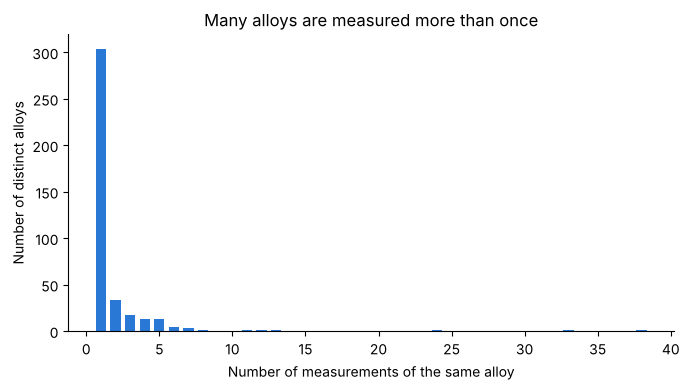

22.8% of distinct alloys have more than one measurement.


In [11]:
# Plot: how many compositions appear once, twice, three times, ...
counts = rows_per_comp.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(counts.index, counts.values, color=COLOR_BLUE, width=0.7)
ax.set_xlabel("Number of measurements of the same alloy")
ax.set_ylabel("Number of distinct alloys")
ax.set_title("Many alloys are measured more than once")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
os.makedirs("figures", exist_ok=True)
plt.savefig("figures/fig1_duplicates.png", dpi=300)
plt.show()

share_repeated = (rows_per_comp > 1).mean() * 100
print(f"{share_repeated:.1f}% of distinct alloys have more than one measurement.")

**Look closely at the list of most-repeated alloys.** You may see pairs like `Al0.071-Co0.232-...` and `Al0.07-Co0.233-...`. These are practically the *same* alloy, written with slightly different numbers in different papers. Our exact `composition_id` treats them as different, so they can still "leak" between training and test sets. That is one reason we also test with the stricter `system_id` grouping, which keeps the whole alloy family together.

> **📝 For your paper (Methods → Dataset):** Report the cleaning numbers from Step 4 (rows after each rule) and the numbers above (measurements vs. distinct compositions vs. element systems). Figure 1 can be this histogram.

## Step 6 — Compute physics-based features (descriptors)

A **feature** is a number that describes each alloy and that the model uses as input. We use two kinds:

**(a) Element fractions:** one column per element (e.g. `frac_Al = 0.077`).

**(b) Physics descriptors**, the classic quantities metallurgists use to understand HEAs. For an alloy with atomic fractions $c_i$:

| Descriptor | Formula | Physical meaning |
|---|---|---|
| Atomic size mismatch $\delta$ | $100\sqrt{\sum_i c_i \left(1 - r_i/\bar r\right)^2}$, with $\bar r = \sum_i c_i r_i$ | Lattice distortion → **solid-solution strengthening** |
| Mixing entropy $\Delta S_{mix}$ | $-R\sum_i c_i \ln c_i$ | How "high-entropy" the alloy is |
| Valence electron concentration VEC | $\sum_i c_i\,\mathrm{VEC}_i$ | Predicts **FCC** (VEC ≥ 8) vs **BCC** (VEC < 6.87) |
| Mean electronegativity $\bar\chi$ | $\sum_i c_i \chi_i$ | Chemical bonding tendency |
| Electronegativity difference $\Delta\chi$ | $\sqrt{\sum_i c_i(\chi_i-\bar\chi)^2}$ | Tendency to form compounds |
| Mean melting point $\bar T_m$ | $\sum_i c_i T_{m,i}$ | Stronger bonding → higher strength |
| Number of elements | count of $c_i > 0$ | |

The element properties ($r_i$, $\chi_i$, $T_{m,i}$) come from the `pymatgen` library.

In [12]:
R_GAS = 8.314  # gas constant, J/(mol·K)

def valence_electrons(symbol):
    '''
    VEC of one element as used in the HEA literature:
    for transition metals it equals the group number (e.g. Fe = 8, Ni = 10),
    for main-group elements it is group - 10 (e.g. Al = 3, Si = 4).
    '''
    group = Element(symbol).group
    return group if group <= 12 else group - 10

def element_radius(symbol):
    '''Metallic radius (Å) if pymatgen has it, otherwise the atomic radius.'''
    el = Element(symbol)
    # pymatgen warns when an element (e.g. C, Si) has no metallic radius;
    # that is expected, so we hide the warning and use the atomic radius instead.
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        radius = el.metallic_radius
    if radius is None or radius == 0:
        radius = el.atomic_radius
    return float(radius)

# Look up the properties ONCE for every element (faster than repeating it per row)
element_table = pd.DataFrame({
    "radius":        {el: element_radius(el)             for el in all_elements},
    "electroneg":    {el: float(Element(el).X)           for el in all_elements},
    "melting_K":     {el: float(Element(el).melting_point) for el in all_elements},
    "vec":           {el: valence_electrons(el)          for el in all_elements},
})
element_table

,radius,electroneg,melting_K,vec
Al,1.43,1.61,933.47,3
C,0.70,2.55,3800.00,4
Ca,1.97,1.00,1115.00,2
Co,1.25,1.88,1768.00,9
Cr,1.28,1.66,2180.00,6
Cu,1.28,1.90,1357.77,11
Fe,1.26,1.83,1811.00,8
Hf,1.59,1.30,2506.00,4
Li,1.52,0.98,453.69,1
Mg,1.60,1.31,923.00,2


Always sanity-check a lookup table like this: Al should have VEC = 3, Fe = 8, Ni = 10, and W should have the highest melting point (≈ 3695 K).

In [13]:
def physics_descriptors(comp):
    '''Compute the physics descriptors for one alloy composition (a dict of fractions).'''
    elements  = list(comp.keys())
    c         = np.array([comp[el] for el in elements])                # fractions
    r         = element_table.loc[elements, "radius"].values            # radii
    chi       = element_table.loc[elements, "electroneg"].values        # electronegativities
    tm        = element_table.loc[elements, "melting_K"].values         # melting points
    vec       = element_table.loc[elements, "vec"].values               # valence electrons

    r_mean    = np.sum(c * r)
    chi_mean  = np.sum(c * chi)

    return {
        "delta_size_mismatch": 100 * np.sqrt(np.sum(c * (1 - r / r_mean) ** 2)),
        "S_mix":               -R_GAS * np.sum(c * np.log(c)),
        "VEC":                 np.sum(c * vec),
        "chi_mean":            chi_mean,
        "delta_chi":           np.sqrt(np.sum(c * (chi - chi_mean) ** 2)),
        "Tm_mean":             np.sum(c * tm),
        "r_mean":              r_mean,
        "n_elements":          len(elements),
    }

# Try it on one alloy: the famous Cantor alloy CoCrFeMnNi
print(physics_descriptors(parse_formula("Co1 Cr1 Fe1 Mn1 Ni1")))

{'delta_size_mismatch': np.float64(1.1223917161691224), 'S_mix': np.float64(13.380866803977112), 'VEC': np.float64(8.0), 'chi_mean': np.float64(1.766), 'delta_chi': np.float64(0.1383618444514238), 'Tm_mean': np.float64(1801.2000000000003), 'r_mean': np.float64(1.26), 'n_elements': 5}


For the equiatomic Cantor alloy, $\Delta S_{mix}$ should be $R\ln 5 \approx 13.4$ J/(mol·K). If you see that number, the code works.

Now we build the complete **feature table** `X` (inputs) and the **target** `y` (what we predict).

In [14]:
# (a) Element fractions: one column per element, 0 if the element is absent
fractions = pd.DataFrame(list(clean["composition"])).fillna(0)
fractions.columns = ["frac_" + el for el in fractions.columns]

# (b) Physics descriptors
physics = pd.DataFrame(list(clean["composition"].apply(physics_descriptors)))

# (c) Test and processing information as 0/1 columns ("one-hot encoding")
#     e.g. test_type "C" becomes a column test_C that is 1 for compression tests
test_info = pd.get_dummies(clean[["test_type", "processing"]], prefix=["test", "proc"], dtype=int)

# Put everything side by side into one table
X = pd.concat([fractions, physics, test_info], axis=1)
y = clean["yield_strength_MPa"].values

print("Feature table X:", X.shape[0], "rows x", X.shape[1], "features")
print("Target y: yield strength, from", y.min(), "to", y.max(), "MPa")

# Keep the lists of column names, we will compare feature sets later
FRACTION_COLS = list(fractions.columns)
PHYSICS_COLS  = list(physics.columns)
TEST_COLS     = list(test_info.columns)

Feature table X: 722 rows x 42 features
Target y: yield strength, from 62.0 to 3416.0 MPa


## Step 7 — Three ways to test a model

We use **5-fold cross-validation**: the data is cut into 5 parts; the model is trained on 4 parts and tested on the 5th, and this is repeated 5 times so that every row is tested exactly once.

The question is **how** we cut the data:

| Strategy | How rows are split | What it measures |
|---|---|---|
| **Random** | Rows shuffled randomly | Copies of the same alloy can be in train *and* test → optimistic |
| **Grouped by composition** | All rows of one composition stay together | Can the model predict an alloy it has *never* seen? |
| **Grouped by element system** | All alloys of one element family stay together | Can the model predict a *new family* of alloys? (hardest, most realistic for discovery) |

`GroupKFold` from scikit-learn does the grouped splitting for us. We just give it the group labels.

In [15]:
# The three splitting strategies, stored in a dictionary so we can loop over them
splitters = {
    "Random":               (KFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED), None),
    "Grouped (composition)": (GroupKFold(n_splits=5), clean["composition_id"].values),
    "Grouped (system)":      (GroupKFold(n_splits=5), clean["system_id"].values),
}

## Step 8 — The models

We compare three models, from simplest to most flexible. Including a simple model is important: if a complex model is not better than a simple one, the complexity is not justified.

* **Ridge regression:** a straight-line (linear) model. Inputs are scaled first with `StandardScaler` because linear models are sensitive to the size of the numbers.
* **Random forest:** many decision trees averaged together. A robust, popular choice for small tabular datasets.
* **XGBoost:** gradient-boosted trees, often the most accurate on tabular data.

In [16]:
def make_models():
    '''Create fresh (untrained) copies of the three models.'''
    return {
        "Ridge (linear)": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
        "Random forest":  RandomForestRegressor(n_estimators=300, random_state=RANDOM_SEED, n_jobs=-1),
        "XGBoost":        XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=5,
                                       subsample=0.8, colsample_bytree=0.8,
                                       random_state=RANDOM_SEED, n_jobs=-1),
    }

def evaluate(y_true, y_pred):
    '''Three standard error measures. R² closer to 1 = better; MAE and RMSE smaller = better.'''
    return {
        "R2":        r2_score(y_true, y_pred),
        "MAE (MPa)": mean_absolute_error(y_true, y_pred),
        "RMSE (MPa)": np.sqrt(mean_squared_error(y_true, y_pred)),
    }

**What the numbers mean:**
* **R²** (coefficient of determination): 1.0 = perfect, 0 = no better than always guessing the average strength.
* **MAE** (mean absolute error): the typical error in MPa. Easy to explain to materials scientists.
* **RMSE** (root mean squared error): like MAE but punishes large errors more.

Now the main experiment: every model × every splitting strategy. `cross_val_predict` gives us, for every row, the prediction made when that row was in the **test** part. This may take a minute.

In [17]:
results = []        # list of result rows, turned into a table at the end
predictions = {}    # keep the predictions for plotting

for split_name, (splitter, groups) in splitters.items():
    for model_name, model in make_models().items():
        # Predict every row while it is in the test fold
        y_pred = cross_val_predict(model, X, y, cv=splitter, groups=groups)

        # Score the predictions and remember them
        scores = evaluate(y, y_pred)
        results.append({"Split": split_name, "Model": model_name, **scores})
        predictions[(split_name, model_name)] = y_pred
        print(f"{split_name:24s} | {model_name:15s} | R2 = {scores['R2']:.3f} | MAE = {scores['MAE (MPa)']:.0f} MPa")

results_table = pd.DataFrame(results)

Random                   | Ridge (linear)  | R2 = 0.453 | MAE = 306 MPa


Random                   | Random forest   | R2 = 0.696 | MAE = 226 MPa


Random                   | XGBoost         | R2 = 0.730 | MAE = 212 MPa
Grouped (composition)    | Ridge (linear)  | R2 = 0.479 | MAE = 315 MPa


Grouped (composition)    | Random forest   | R2 = 0.627 | MAE = 261 MPa


Grouped (composition)    | XGBoost         | R2 = 0.684 | MAE = 242 MPa
Grouped (system)         | Ridge (linear)  | R2 = 0.447 | MAE = 326 MPa


Grouped (system)         | Random forest   | R2 = 0.486 | MAE = 309 MPa


Grouped (system)         | XGBoost         | R2 = 0.536 | MAE = 291 MPa


In [18]:
# A neat summary table: rows = models, columns = splitting strategies
summary_r2  = results_table.pivot(index="Model", columns="Split", values="R2")[list(splitters)]
summary_mae = results_table.pivot(index="Model", columns="Split", values="MAE (MPa)")[list(splitters)]

print("R² (higher is better)")
display(summary_r2.round(3))
print("MAE in MPa (lower is better)")
display(summary_mae.round(0))

# Save the table so you can copy it into your paper
os.makedirs("results", exist_ok=True)
results_table.round(4).to_csv("results/table1_baseline_results.csv", index=False)

R² (higher is better)


Split,Random,Grouped (composition),Grouped (system)
Model,,,
Random forest,0.696,0.627,0.486
Ridge (linear),0.453,0.479,0.447
XGBoost,0.730,0.684,0.536


MAE in MPa (lower is better)


Split,Random,Grouped (composition),Grouped (system)
Model,,,
Random forest,226.0,261.0,309.0
Ridge (linear),306.0,315.0,326.0
XGBoost,212.0,242.0,291.0


### Step 8b — Look at the predictions (parity plots)

A **parity plot** shows predicted vs. measured strength. Perfect predictions lie on the diagonal line. We show the random-forest results for all three splitting strategies side by side.

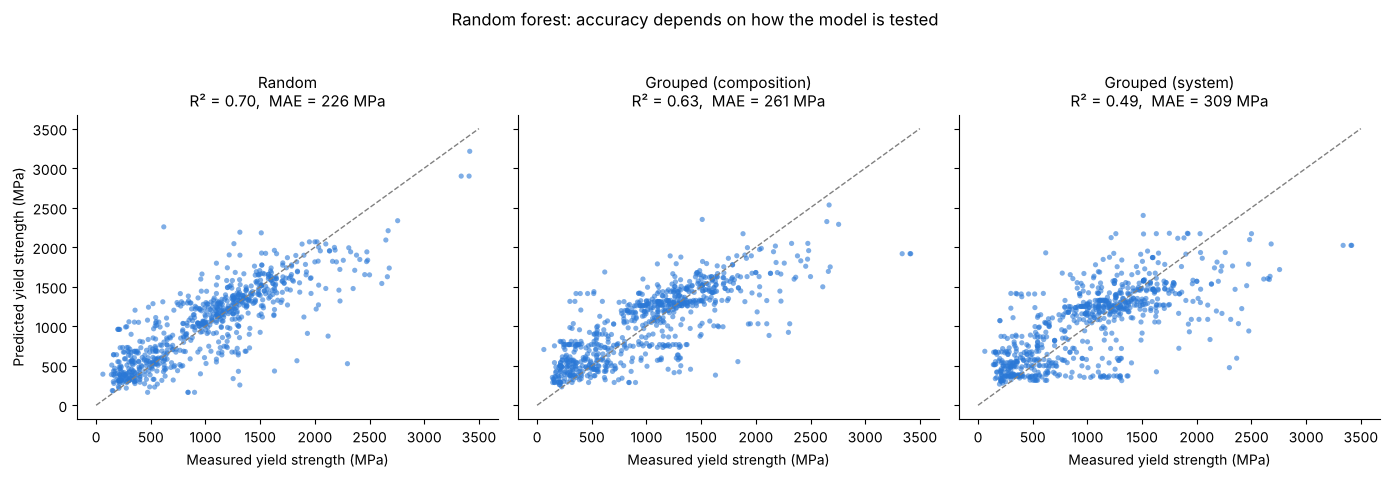

In [19]:
model_to_plot = "Random forest"
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), sharex=True, sharey=True)

for ax, split_name in zip(axes, splitters):
    y_pred = predictions[(split_name, model_to_plot)]
    r2  = r2_score(y, y_pred)
    mae = mean_absolute_error(y, y_pred)

    ax.scatter(y, y_pred, s=14, alpha=0.6, color=COLOR_BLUE, edgecolor="none")
    ax.plot([0, 3500], [0, 3500], color="gray", linewidth=1, linestyle="--")   # perfect-prediction line
    ax.set_title(f"{split_name}\nR² = {r2:.2f},  MAE = {mae:.0f} MPa", fontsize=11)
    ax.set_xlabel("Measured yield strength (MPa)")
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Predicted yield strength (MPa)")
plt.suptitle(f"{model_to_plot}: accuracy depends on how the model is tested", y=1.03)
plt.tight_layout()
plt.savefig("figures/fig2_parity_three_splits.png", dpi=300, bbox_inches="tight")
plt.show()

**What to look for:** with the random split, the points hug the diagonal. With the grouped splits, they spread out much more. *The model is the same; only the honesty of the test changed.*

> **📝 For your paper (Results):** Report the R²/MAE table (saved in `results/table1_baseline_results.csv`) and Figure 2. The **grouped** numbers are the ones that describe how well the model would work on a *new* alloy, so state that clearly. Cite Borg *et al.* (2020) for the data and MD-HIT (Li *et al.*, *npj Comput. Mater.* 2024) for the general redundancy problem.

## Step 9 — Which features help most?

Do the physics descriptors actually help, or are the raw element fractions enough? We test the random forest with three feature sets, using the **grouped-by-composition** split (the honest one).

In [20]:
feature_sets = {
    "Element fractions only":       FRACTION_COLS + TEST_COLS,
    "Physics descriptors only":     PHYSICS_COLS + TEST_COLS,
    "Fractions + physics (all)":    FRACTION_COLS + PHYSICS_COLS + TEST_COLS,
}

splitter, groups = splitters["Grouped (composition)"]
feature_results = []

for set_name, columns in feature_sets.items():
    model = RandomForestRegressor(n_estimators=300, random_state=RANDOM_SEED, n_jobs=-1)
    y_pred = cross_val_predict(model, X[columns], y, cv=splitter, groups=groups)
    feature_results.append({"Feature set": set_name, "Number of features": len(columns), **evaluate(y, y_pred)})

pd.DataFrame(feature_results).round(3)

,Feature set,Number of features,R2,MAE (MPa),RMSE (MPa)
0,Element fractions only,34,0.677,244.775,332.747
1,Physics descriptors only,16,0.647,255.331,347.953
2,Fractions + physics (all),42,0.627,260.941,357.633


**Be careful when interpreting small differences.** These numbers come from a single 5-fold run. A difference of about 0.03 in R² can be pure chance (a different random seed could reverse it). Before claiming "feature set A is better than B" in the paper, we will repeat the experiment with several seeds and report the average ± standard deviation (Notebook 2). Physics descriptors are still valuable even when accuracy is similar: they are far easier to *interpret* (Step 9b and Notebook 4).

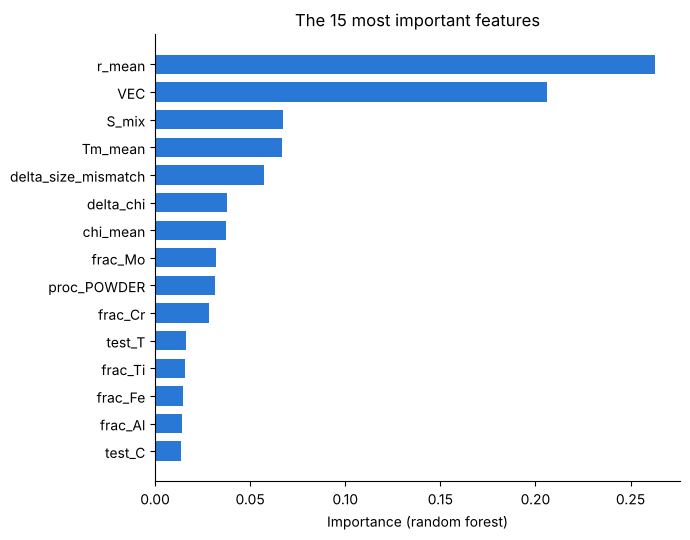

In [21]:
# Train one random forest on ALL data to see which features it relies on most.
# (This is for interpretation only; the accuracy numbers above come from cross-validation.)
rf_full = RandomForestRegressor(n_estimators=300, random_state=RANDOM_SEED, n_jobs=-1)
rf_full.fit(X, y)

importance = pd.Series(rf_full.feature_importances_, index=X.columns).sort_values()
top15 = importance.tail(15)

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(top15.index, top15.values, color=COLOR_BLUE, height=0.7)
ax.set_xlabel("Importance (random forest)")
ax.set_title("The 15 most important features")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("figures/fig3_feature_importance.png", dpi=300)
plt.show()

Random-forest importances are a quick first look. In a later notebook we will use **SHAP**, a more reliable method that also tells us *in which direction* each feature pushes the strength (e.g. "higher size mismatch → higher strength").

## Step 10 — Is the hardness idea feasible?

The main idea of the paper is to **use hardness data to help predict yield strength**. The physics behind it is Tabor's relation for metals:

$$\sigma_y \approx \frac{H_V \times 9.807}{3}$$

($H_V$ is Vickers hardness in kgf/mm²; multiplying by 9.807 converts it to MPa.)

This idea only works if:
1. there are alloys with **both** hardness and yield strength, so we can check the relation, and
2. there are **extra** alloys that have hardness but **no** yield strength, because these are the alloys hardness would teach us about.

Let's count them.

In [22]:
# Hardness data: all rows with a hardness value (any test, room temperature is assumed for HV)
hard = df[df["hardness_HV"].notna()].copy()
hard["composition_id"] = hard["formula"].apply(parse_formula).apply(make_composition_id)

# Average the values per composition (the same alloy can appear several times)
hv_per_alloy = hard.groupby("composition_id")["hardness_HV"].mean()
ys_per_alloy = clean.groupby("composition_id")["yield_strength_MPa"].mean()

alloys_with_hv   = set(hv_per_alloy.index)
alloys_with_ys   = set(ys_per_alloy.index)
alloys_with_both = alloys_with_hv & alloys_with_ys
alloys_hv_only   = alloys_with_hv - alloys_with_ys

print(f"Alloys with room-temperature yield strength:   {len(alloys_with_ys)}")
print(f"Alloys with hardness:                          {len(alloys_with_hv)}")
print(f"Alloys with BOTH (to check Tabor's relation):  {len(alloys_with_both)}")
print(f"Alloys with hardness ONLY (extra information): {len(alloys_hv_only)}")

Alloys with room-temperature yield strength:   394
Alloys with hardness:                          377
Alloys with BOTH (to check Tabor's relation):  188
Alloys with hardness ONLY (extra information): 189


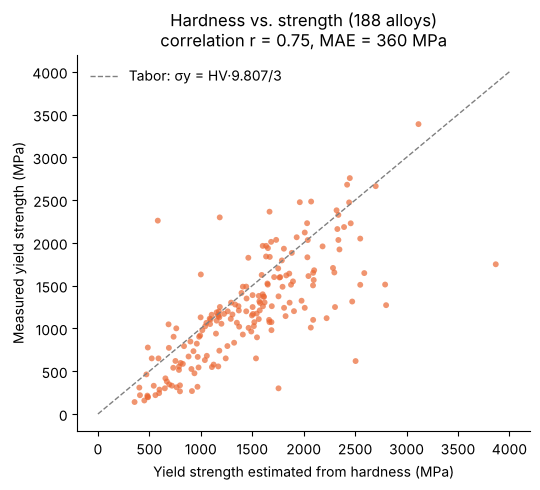

In [23]:
# Compare measured yield strength with the Tabor estimate for alloys that have both
both = pd.DataFrame({
    "HV":          hv_per_alloy[list(alloys_with_both)],
    "YS_measured": ys_per_alloy[list(alloys_with_both)],
})
both["YS_tabor"] = both["HV"] * 9.807 / 3

r2_tabor  = r2_score(both["YS_measured"], both["YS_tabor"])
mae_tabor = mean_absolute_error(both["YS_measured"], both["YS_tabor"])
corr      = np.corrcoef(both["HV"], both["YS_measured"])[0, 1]

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(both["YS_tabor"], both["YS_measured"], s=18, alpha=0.7, color=COLOR_ORANGE, edgecolor="none")
ax.plot([0, 4000], [0, 4000], color="gray", linestyle="--", linewidth=1, label="Tabor: σy = HV·9.807/3")
ax.set_xlabel("Yield strength estimated from hardness (MPa)")
ax.set_ylabel("Measured yield strength (MPa)")
ax.set_title(f"Hardness vs. strength ({len(both)} alloys)\ncorrelation r = {corr:.2f}, MAE = {mae_tabor:.0f} MPa")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("figures/fig4_hardness_vs_strength.png", dpi=300)
plt.show()

**How to interpret this:**
* A **high correlation** means hardness carries real information about strength, which is good for our idea.
* Points will not sit exactly on the line: hardness and yield strength were often measured in different papers, after different heat treatments. That scatter is exactly why we need ML rather than just Tabor's formula.
* The number of **hardness-only alloys** tells us how much *extra* knowledge hardness could add. If it is comparable to the number of yield-strength alloys, the transfer idea is worth pursuing.

> **📝 For your paper:** This plot and these counts justify the main contribution. In Notebook 2 we will test *how* to best use the hardness data (e.g. Tabor estimate as an extra feature, or pre-training on hardness) under grouped validation.

## Step 11 — Save the cleaned data

We save the cleaned table and the feature table so the next notebooks can start from here without repeating all the steps.

In [24]:
# Cleaned measurements (without the dictionary column, which CSV files cannot store well)
clean.drop(columns=["composition"]).to_csv("data/clean_yield_strength_RT.csv", index=False)

# Features + target + group labels in one file
features_out = X.copy()
features_out["yield_strength_MPa"] = y
features_out["composition_id"]     = clean["composition_id"].values
features_out["system_id"]          = clean["system_id"].values
features_out.to_csv("data/features_yield_strength_RT.csv", index=False)

# Hardness per alloy, for Notebook 2
hv_per_alloy.rename("hardness_HV_mean").to_csv("data/hardness_per_alloy.csv")

print("Saved files:")
for f in sorted(os.listdir("data")):
    print("  data/" + f)

Saved files:
  data/MPEA_dataset.csv
  data/clean_yield_strength_RT.csv
  data/features_yield_strength_RT.csv
  data/hardness_per_alloy.csv


## Summary — what we learned

1. The dataset has many repeated measurements of the same alloys.
2. A **random** split gives an optimistic accuracy. **Grouped** splits give lower, honest numbers, and the *element-system* split shows how hard it is to predict a completely new alloy family.
3. Physics descriptors and element fractions can be compared fairly only under grouped validation.
4. There is a usable amount of hardness data, including alloys that have no yield-strength measurement. That is the opportunity our paper builds on.

### Next notebooks
* **Notebook 2:** Hardness → strength transfer (the main contribution), always evaluated with grouped splits.
* **Notebook 3:** Uncertainty: does the model *know* when it is likely to be wrong?
* **Notebook 4:** SHAP interpretation and final paper figures.

### Exercises to build your skills (optional)
* Change the room-temperature window in Step 4 to 15–35 °C. Do the results change?
* Keep only **compression** tests. Is the model more accurate?
* Change `n_splits=5` to `n_splits=10`. What happens to the scores?